In [1]:
import pysam
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import argparse
import os
from collections import Counter

def plot_insertions(counts_df, total_genome_length, mode="mb", ax=None,):
    if ax is None:
        fig, ax = plt.subplots(figsize=(16, 6))
    count_df = counts_df.copy()
    # Plot Mb if mb specified as mode; else default to plotting bp
    if mode.lower() == "mb":
        position_plot_col = "position_mb"
        total_genome_length = total_genome_length / 1_000_000
    elif mode.lower() == "b":
        position_plot_col = "position"
    else:
        raise ValueError("Invalid mode for plotting! Options are mb for Mb scale or b for bp scale")
    # Set the count threshold for displaying labels.
    # A threshold of 0 will label every single point.
    label_threshold = 0
    # Filter the data to select points that meet the label threshold.
    labels_df = count_df[count_df['count'] >= label_threshold]
    print(f"  - Found {len(labels_df)} sites with counts >= {label_threshold} to label.")
    markerline, stemlines, baseline = ax.stem(
        count_df[position_plot_col],
        count_df['count'],
        linefmt='grey',
        markerfmt='o',
        basefmt=' '
    )
    plt.setp(markerline, 'markersize', 3, 'color', 'royalblue')

    # Add labels to stem plot
    for index, row in labels_df.iterrows():
        ax.text(
            x=row[position_plot_col] + 0.01,
            y=row['count'],
            s=f"{int(row['position'])}, {int(row['count'])}times",
            color='blue',
            fontsize=9
        )


    # Title and labels for ax
    ax.set_ylabel("Insertion Counts", fontsize=12)
    ax.set_ylim(bottom=0)

    # Optional x-axis limit
    if total_genome_length > 0:
        ax.set_xlim(left=0, right=total_genome_length)
    else:
        ax.set_xlim(left=0)
    return ax

def plot_triangle(target_coordinate, ax):
    # Plot a red triangle at the target site
    x_range = ax.get_xlim()[1] - ax.get_xlim()[0]
    triangle_width = x_range * 0.01
    # triangle_height = ax.get_ylim()[1] * 0.02  
    triangle_height = ax.get_ylim()[1] * 0.022
    # print(triangle_width, triangle_height, x_range)

    triangle = patches.Polygon(
        [[target_coordinate - triangle_width / 2, -triangle_height],
        [target_coordinate + triangle_width / 2, -triangle_height],
        [target_coordinate, 0]],
        transform=ax.transData,
        clip_on=False,
        color='red',
        alpha=1
    )
    ax.add_patch(triangle)

# def main():
# Set a professional style for the plots.
sns.set_style("whitegrid")

# --- Step 2: Parameter Configuration ---
# Specify the path to the SAM/BAM file for analysis.

parser = argparse.ArgumentParser(
    description="Script to plot insertion map results against a reference genome"
)
parser.add_argument(
    "-d", "--wk_dir", required=True,
    help="Working directory path. Must contain a file called aligned_contigs.bam"
)
# parser.add_argument(
#     "-o", "--out_dir", required=True,
#     help="Directory to write the output plots to"
# )
parser.add_argument(
    "-t", "--title", required=False,
    help="Title for plot"
)
parser.add_argument(
    "-x", "--target_coordinate", required=False, type=int,
    help="Target coordinate for integrations in bp"
)
parser.add_argument(
    "-w", "--zoom_window_size", required=False, type=int, default=100,
    help="If target coordinate provided: window size for additional zoomed in plot around target coordinate"
)
parser.add_argument(
    "--on_target_threshold", required=False, type=int, default=10,
    help="If target coordinate provided: how many bp away from target site on either side to still consider as on target"
)
parser.add_argument(
    "--plot_coverage",
    action="store_true",
    help="Include this flag to enable coverage plotting. Requires a file called raw_reads_coverage.tsv in wk_dir"
)

args = parser.parse_args([
    "-x", '3843421',
    "-d", "../data/250805_pipeline_test",
    "--plot_coverage"
])

alignment_file = os.path.join(args.wk_dir, "aligned_contigs.bam")
assert os.path.exists(alignment_file), "Working dir must contain aligned_contigs.bam!"
out_dir = os.path.join(args.wk_dir, "plots")
if not os.path.exists(out_dir):
    os.makedirs(out_dir, exist_ok=True)

# Set default title if not provided
if not args.title:
    args.title = f"Insertion map for {alignment_file}"

print(f"Step 2: Set alignment file to '{alignment_file}'")

# --- Step 3: Data Processing (Extracting Insertion Sites and Genome Length) ---
print("\nStep 3: Processing alignment file...")

# Counter for tracking filtered reads.
filter_counts = Counter({
    "unmapped": 0,
    "low_mapq": 0,
    "secondary": 0,
    "supplementary": 0,
})
insertion_sites, reference_names = [], []
# total_genome_length = 0

# Open the SAM/BAM file once to process reads and get header info.
with pysam.AlignmentFile(alignment_file, "r") as samfile:
    # Get total genome length from the SAM/BAM header.
    if samfile.header.lengths:
        total_genome_lengths = dict(zip(samfile.header.references, samfile.header.lengths))
        print(f"Total genome lengths from header:")
        for genome, length in total_genome_lengths.items():
            print(f"\t{genome}: {length:,} bp")

    # Process all aligned reads in the file.
    for read in samfile.fetch(until_eof=True):
        # Check which filtering condition the read meets.
        if read.is_unmapped:
            filter_counts["unmapped"] += 1
            continue
        # MAPQ=0 often means a read maps to multiple locations.
        if read.mapping_quality == 0:
            filter_counts["low_mapq"] += 1
            continue
        # Secondary/supplementary alignments are alternative mappings for the same read.
        if read.is_secondary:
            filter_counts["secondary"] += 1
            continue
        if read.is_supplementary:
            filter_counts["supplementary"] += 1
            continue

        # For reads that pass the filters, get the 5' end position.
        pos = read.reference_end - 1 if read.is_reverse else read.reference_start
        insertion_sites.append(pos)
        reference_names.append(read.reference_name)

# Report the filtering statistics.
total_reads = sum(filter_counts.values()) + len(insertion_sites)
print(f"Total reads processed: {total_reads:,}")
for reason, count in filter_counts.items():
    print(f"  - {reason:14s}: {count:,} reads filtered out")
print(f"  - Kept for analysis: {len(insertion_sites):,} reads")


# --- Step 4: Data Aggregation and Formatting ---
print("\nStep 4: Aggregating data...")

positions_df = pd.DataFrame([insertion_sites, reference_names], index=['position', 'reference']).T

# Convert to 1-based indexing
positions_df["position"] += 1

# Convert the results into a DataFrame for plotting.
counts_df = pd.DataFrame(positions_df.groupby("reference")["position"].value_counts()).reset_index()

# Add a column for plotting in Megabases (Mb).
counts_df['position_mb'] = counts_df['position'] / 1_000_000
# NOTE: The log10_count column is calculated but not used in the plot, so it's removed for clarity.
print("  - Data aggregation complete.")

Step 2: Set alignment file to '../data/250805_pipeline_test/aligned_contigs.bam'

Step 3: Processing alignment file...
Total genome lengths from header:
	P7YMY9_pSES0099: 9,503 bp
	monomeric_BAC_for_plate_scrape_13kb: 13,755 bp
	Manually_Adjusted_Seq_of_HalfKan_Reporter_Strain_SLMQRT_4_dnaSES0085_no_BAC: 4,633,946 bp
Total reads processed: 468
  - unmapped      : 8 reads filtered out
  - low_mapq      : 0 reads filtered out
  - secondary     : 0 reads filtered out
  - supplementary : 0 reads filtered out
  - Kept for analysis: 460 reads

Step 4: Aggregating data...
  - Data aggregation complete.



Step 5: Creating genome-wide plots...
  - Found 2 sites with counts >= 0 to label.


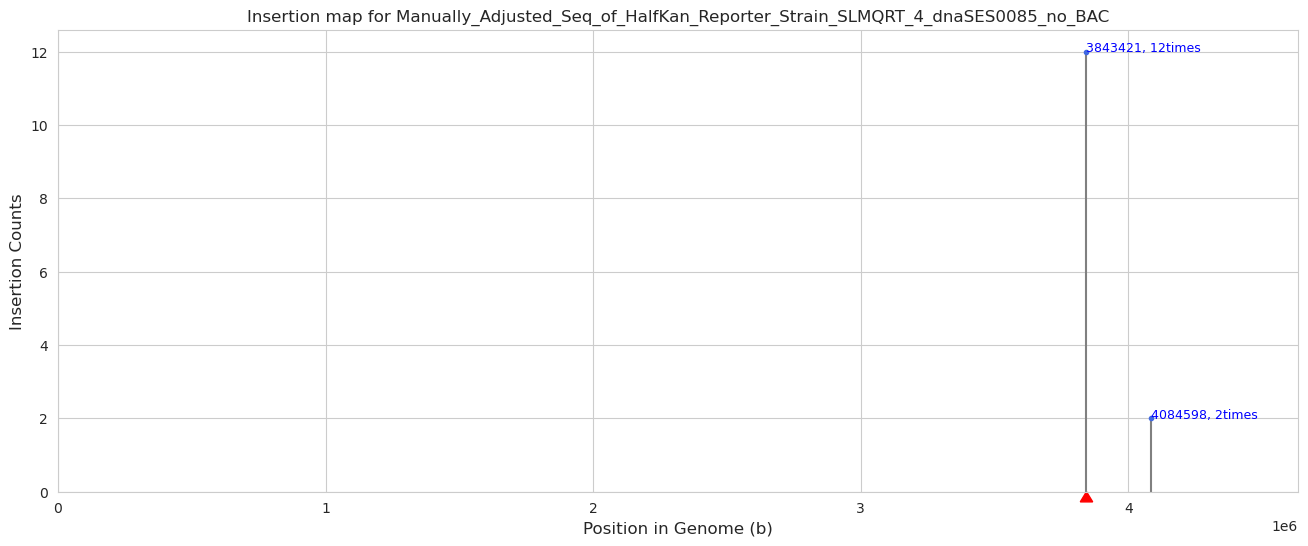

  - Found 11 sites with counts >= 0 to label.


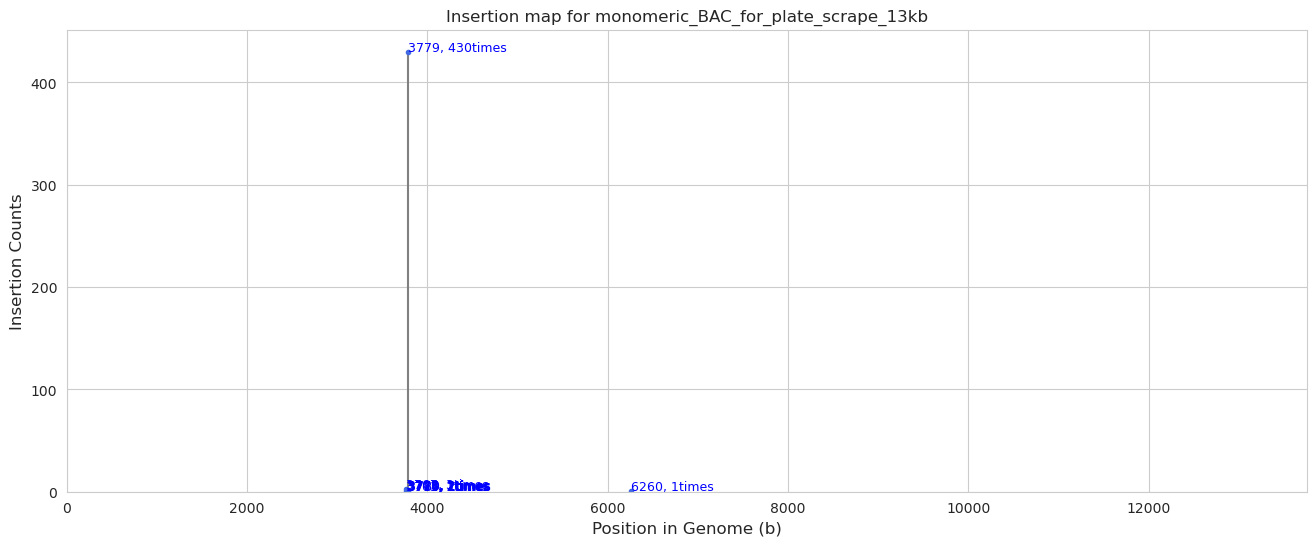

In [2]:
# --- Step 5: Visualization (Labeling Peaks) ---
print("\nStep 5: Creating genome-wide plots...")
##### Make the high level insertion map
reference_genome_name = "Manually_Adjusted_Seq_of_HalfKan_Reporter_Strain_SLMQRT_4_dnaSES0085_no_BAC"

for reference in counts_df["reference"].unique():

    ax = plot_insertions(
        counts_df[counts_df["reference"]==reference], 
        total_genome_lengths[reference], 
        mode="b")
    if reference == reference_genome_name:
        plot_triangle(args.target_coordinate, ax)
    ax.set_title(args.title, fontsize=16)
    ax.set_xlabel("Position in Genome (b)", fontsize=12)
    plt.title(f"Insertion map for {reference}")
    plt.show()
    # plt.savefig(os.path.join(out_dir, "alignment_plot.png"), dpi=300)


I extracted the sequences for the 14bp after the intended target site and after 
the observed off-target site, and aligned these

In [3]:
from Bio import pairwise2
from Bio.pairwise2 import format_alignment

# Define the sequences
target = "taagtagacgccta"
off_target = "taagacgtttattc"

# Perform global alignment (Needleman-Wunsch)
alignments = pairwise2.align.globalms(target, off_target, 2, -1, -2, -0.5)

# Print the best alignment
top_alignment = alignments[0]
print(format_alignment(*top_alignment))

taagtagacgccta---
||   |||||..||   
ta---agacgtttattc
  Score=10



/home/jackd/miniconda3/envs/brna/lib/python3.13/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


Plotting insertion map with coverage...
  - Found 2 sites with counts >= 0 to label.
Plotting zoomed in insertion map...
  - Found 1 sites with counts >= 0 to label.
Plotting pie chart...


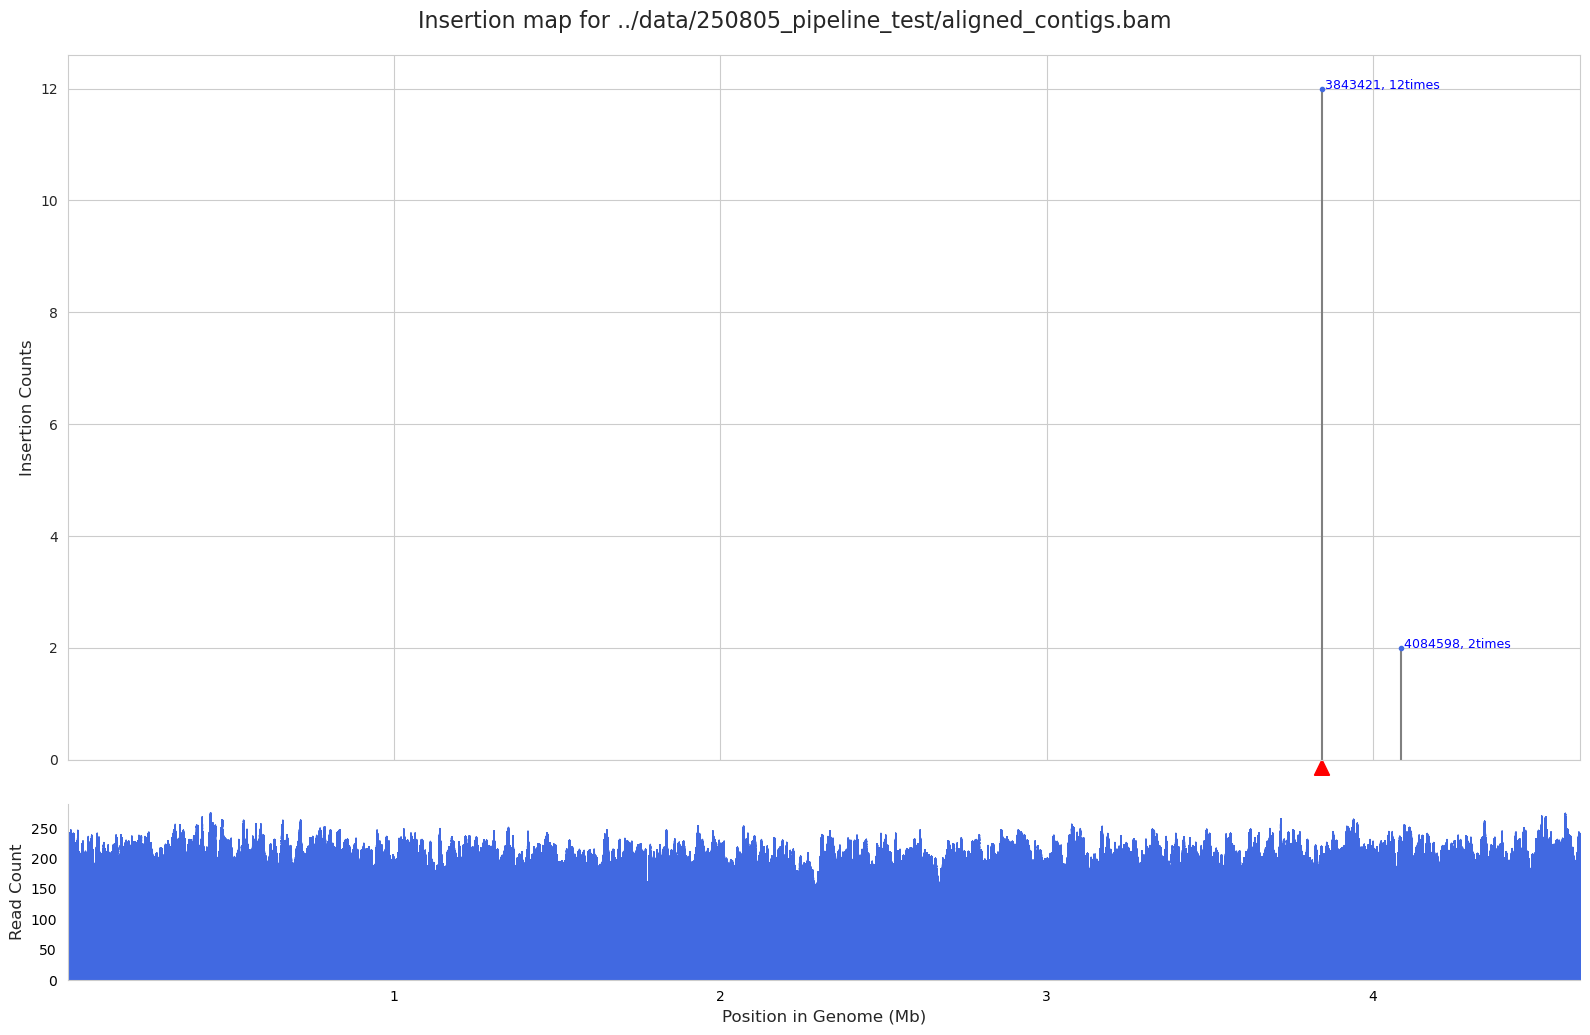

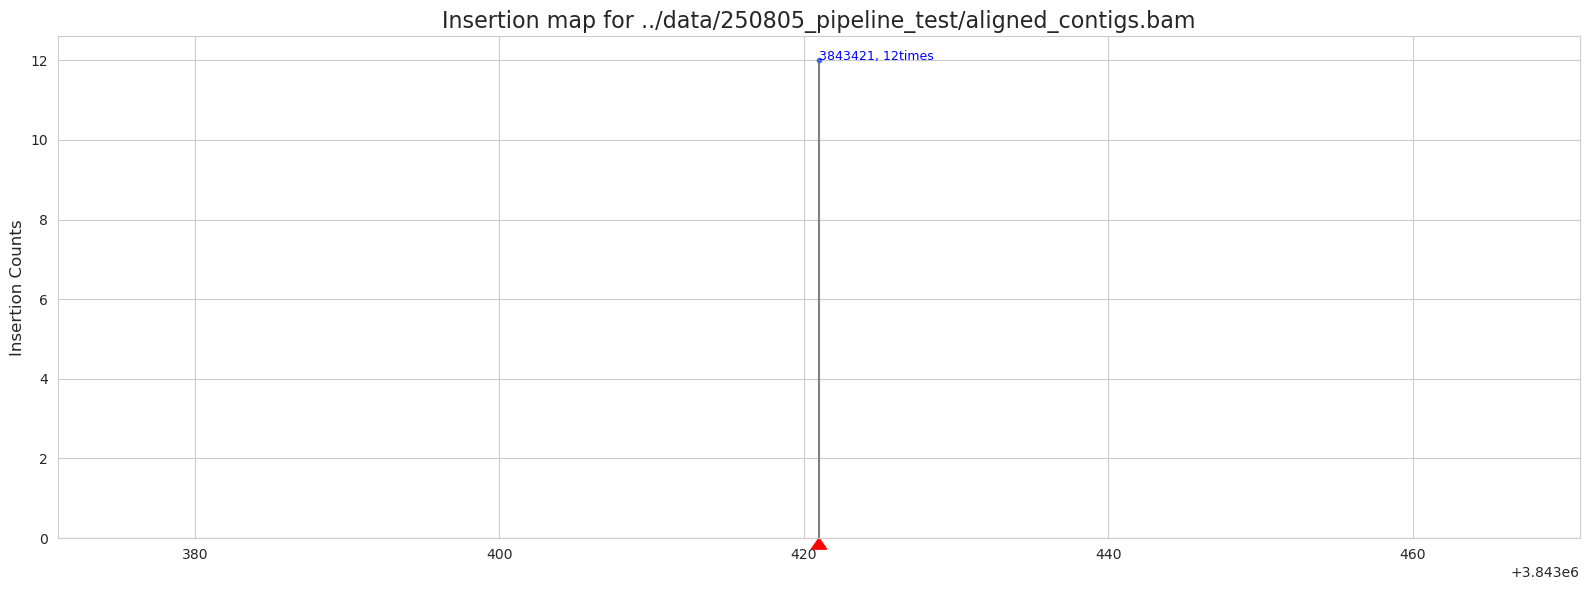

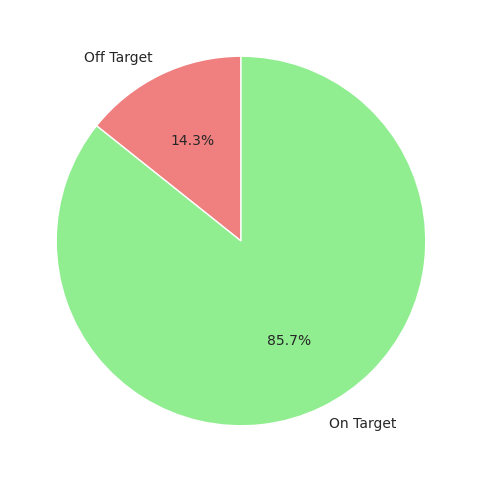

In [4]:
##### If you want to plot coverage below insertion map, this will do that
if args.plot_coverage:
    print("Plotting insertion map with coverage...")
    counts_df_reference = counts_df[counts_df["reference"]==reference_genome_name].copy()
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True, gridspec_kw={'height_ratios': [4, 1]})
    plot_insertions(counts_df_reference, total_genome_lengths[reference_genome_name], mode="mb", ax=ax1)
    plot_triangle(args.target_coordinate / 1_000_000, ax1) # Plot triangle at target site

    # Read dataframe of whole genome coverage
    cov_df = pd.read_csv((os.path.join(args.wk_dir, "raw_reads_coverage.tsv")), sep="\t", header=None)
    cov_df.columns=["chrom", "pos", "depth"]
    cov_df["pos_mb"] = cov_df["pos"] / 1_000_000
    # Subset to only reference genome
    cov_df_ref = cov_df[cov_df["chrom"]==reference_genome_name]
    # Plot coverage below insetion map
    ax2.fill_between(cov_df_ref['pos_mb'], cov_df_ref['depth'], color='royalblue')
    ax2.set_ylabel("Read Count", fontsize=12)
    ax2.set_xlabel("Position in Genome (Mb)", fontsize=12)
    ax2.set_ylim(bottom=0)
    ax2.set_xlim(cov_df_ref["pos_mb"].min(), cov_df_ref["pos_mb"].max())
    ax2.tick_params(
        direction='out',
        length=4,
        width=1,
        colors='black',
        grid_color='none',
        grid_alpha=0.5
    )
    sns.despine(ax=ax2)

    # --- Layout adjustment ---
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.1)  # Increase vertical space between plots
    plt.suptitle(args.title, fontsize=16, y=1.03)
    fig.savefig(os.path.join(out_dir, "alignment_plot_with_coverage.png"), dpi=300)
# If target coordinate provided: save an additional zoomed in plot around 
# that site AND save a pie chart of on target % (on target is defined as 
# give or take args.on_target_threshold from target site [defaults to 10bp])

if args.target_coordinate:
    print("Plotting zoomed in insertion map...")
    # PLOT A ZOOMED IN VERSION OF THE INSERTION MAP
    w = args.zoom_window_size / 2
    xmin, xmax = args.target_coordinate - w, args.target_coordinate + w

    ax = plot_insertions(
        counts_df_reference[(counts_df_reference["position"] >= xmin) & (counts_df_reference["position"] <= xmax)], 
        total_genome_lengths[reference_genome_name],
        mode="b")
    plt.xlim(xmin, xmax)
    plot_triangle(args.target_coordinate, ax)
    plt.title(args.title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "alignment_plot_zoomed.png"), dpi=300)

    # PLOT A PIE CHART SHOWING % OF ON TARGET INTEGRATIONS
    print("Plotting pie chart...")
    def on_target_mapper(pos):
        if (pos >= (args.target_coordinate - args.on_target_threshold)) and (pos <= args.target_coordinate + args.on_target_threshold ):
            return True
        else:
            return False

    counts_df_reference["on_target"] = counts_df_reference["position"].map(on_target_mapper)
    counts = counts_df_reference.groupby('on_target')['count'].sum()
    # Plot pie chart
    plt.figure(figsize=(6, 6))
    counts.plot.pie(
        autopct='%1.1f%%',
        startangle=90,
        labels=['Off Target', 'On Target'],  # Map False to Off, True to On
        colors=['lightcoral', 'lightgreen'],
        # wedgeprops={'edgecolor': 'black'}
    )
    plt.ylabel("")
    plt.savefig(os.path.join(out_dir, "on_target_pie_chart.png"), dpi=300)

# if __name__ == "__main__":
# main()

In [5]:
cov_df_bac.depth.mean()

NameError: name 'cov_df_bac' is not defined

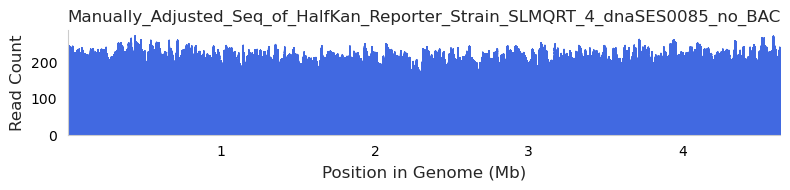

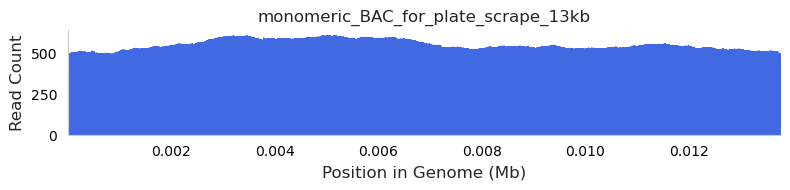

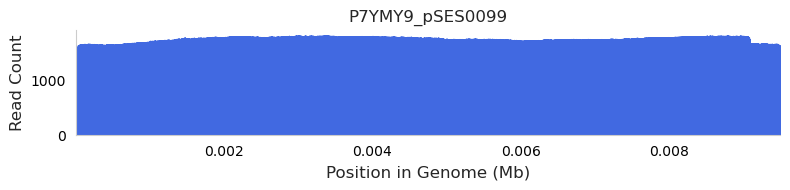

In [ ]:
cov_df.groupby("chrom")["depth"].mean()
# print(args.target_coordinate)
# counts_df_reference

for contig in cov_df["chrom"].unique():
    cov_df_contig = cov_df[cov_df["chrom"]==contig]
    # Plot coverage below insetion map
    fig, ax = plt.subplots(figsize=(8,2))
    ax.fill_between(cov_df_contig['pos_mb'], cov_df_contig['depth'], color='royalblue')
    ax.set_ylabel("Read Count", fontsize=12)
    ax.set_xlabel("Position in Genome (Mb)", fontsize=12)
    ax.set_ylim(bottom=0)
    ax.set_xlim(cov_df_contig["pos_mb"].min(), cov_df_contig["pos_mb"].max())
    ax.tick_params(
        direction='out',
        length=4,
        width=1,
        colors='black',
        grid_color='none',
        grid_alpha=0.5
    )
    sns.despine(ax=ax)
    ax.set_title(contig)

    # --- Layout adjustment ---
    plt.tight_layout()
    plt.show()

## Sub-Analysis: Mapping WHOLE RE-containing reads
We're interested in this for cases where maybe an RE-containing read contains 
mostly BAC, but if you look at the whole read it has some of the genome we can 
map. How many reads are we failing to map because we do the 200bp trimming? My 
guess is not much, since we can see from above that the bulk of the ~460 reads 
that aren't mapped to the reference genome are mapped to some part of the BAC. 
Inspecting these reads manually, it looks like these contain the LE, which
means that these reads are likely coming from circular BACs and thus shouldn't 
be mapping to the genome

In [ ]:
from Bio import SeqIO
records = SeqIO.parse("../data/SLMQRT/RE_contain_contigs.fasta", "fasta")
re_containing_reads = [read.id for read in records]

all_reads = SeqIO.parse("../data/SLMQRT/input/SLMQRT_5_5_dnaSES0086.fastq", "fastq")
re_containing_reads_full = []

for read in all_reads:
    if read.id in re_containing_reads:
        re_containing_reads_full.append(read)

In [ ]:
out_re = "../data/SLMQRT/RE_contain_contigs_full.fasta"
with open(out_re, "w") as output_handle:
    SeqIO.write(re_containing_reads_full, output_handle, "fasta")

In [ ]:
!minimap2 -t 48 -ax map-ont ../data/SLMQRT/input/genome_is110_bac.fasta {out_re} \
| samtools view -bS \
| samtools sort -o ../data/SLMQRT/explore/aligned_contigs_full_reads.bam - \
&& samtools index ../data/SLMQRT/explore/aligned_contigs_full_reads.bam

[M::mm_idx_gen::0.275*1.01] collected minimizers
[M::mm_idx_gen::0.343*1.69] sorted minimizers
[M::main::0.343*1.69] loaded/built the index for 3 target sequence(s)
[M::mm_mapopt_update::0.366*1.64] mid_occ = 11
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 3
[M::mm_idx_stat::0.382*1.62] distinct minimizers: 841501 (98.18% are singletons); average occurrences: 1.034; average spacing: 5.352; total length: 4657204
[M::worker_pipeline::0.611*8.55] mapped 468 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: minimap2 -t 48 -ax map-ont ../data/SLMQRT/input/genome_is110_bac.fasta ../data/SLMQRT/RE_contain_contigs_full.fasta
[M::main] Real time: 0.632 sec; CPU: 5.248 sec; Peak RSS: 0.107 GB


In [ ]:
!head {output_handle}

/bin/bash: -c: line 1: syntax error near unexpected token `newline'
/bin/bash: -c: line 1: `head <_io.TextIOWrapper name='../data/SLMQRT/RE_contain_contigs_full.fasta' mode='w' encoding='UTF-8'>'


In [ ]:
def process_alignment(alignment_file):
# alignment_file = os.path.join(args.wk_dir, "aligned_contigs.bam")
# assert os.path.exists(alignment_file), "Working dir must contain aligned_contigs.bam!"
    # out_dir = os.path.join(args.wk_dir, "plots")
    # if not os.path.exists(out_dir):
    #     os.makedirs(out_dir, exist_ok=True)

    # Set default title if not provided
    # if not args.title:
    #     args.title = f"Insertion map for {alignment_file}"

    print(f"Step 2: Set alignment file to '{alignment_file}'")

    # --- Step 3: Data Processing (Extracting Insertion Sites and Genome Length) ---
    print("\nStep 3: Processing alignment file...")

    # Counter for tracking filtered reads.
    filter_counts = Counter({
        "unmapped": 0,
        "low_mapq": 0,
        "secondary": 0,
        "supplementary": 0,
    })
    insertion_sites, reference_names = [], []
    # total_genome_length = 0

    # Open the SAM/BAM file once to process reads and get header info.
    with pysam.AlignmentFile(alignment_file, "r") as samfile:
        # Get total genome length from the SAM/BAM header.
        if samfile.header.lengths:
            total_genome_lengths = dict(zip(samfile.header.references, samfile.header.lengths))
            print(f"Total genome lengths from header:")
            for genome, length in total_genome_lengths.items():
                print(f"\t{genome}: {length:,} bp")

        # Process all aligned reads in the file.
        for read in samfile.fetch(until_eof=True):
            # Check which filtering condition the read meets.
            if read.is_unmapped:
                filter_counts["unmapped"] += 1
                continue
            # MAPQ=0 often means a read maps to multiple locations.
            if read.mapping_quality == 0:
                filter_counts["low_mapq"] += 1
                continue
            # Secondary/supplementary alignments are alternative mappings for the same read.
            if read.is_secondary:
                filter_counts["secondary"] += 1
                continue
            if read.is_supplementary:
                filter_counts["supplementary"] += 1
                continue

            # For reads that pass the filters, get the 5' end position.
            pos = read.reference_end - 1 if read.is_reverse else read.reference_start
            insertion_sites.append(pos)
            reference_names.append(read.reference_name)

    # Report the filtering statistics.
    total_reads = sum(filter_counts.values()) + len(insertion_sites)
    print(f"Total reads processed: {total_reads:,}")
    for reason, count in filter_counts.items():
        print(f"  - {reason:14s}: {count:,} reads filtered out")
    print(f"  - Kept for analysis: {len(insertion_sites):,} reads")


    # --- Step 4: Data Aggregation and Formatting ---
    print("\nStep 4: Aggregating data...")

    positions_df = pd.DataFrame([insertion_sites, reference_names], index=['position', 'reference']).T

    # Convert to 1-based indexing
    positions_df["position"] += 1

    # Convert the results into a DataFrame for plotting.
    counts_df = pd.DataFrame(positions_df.groupby("reference")["position"].value_counts()).reset_index()

    # Add a column for plotting in Megabases (Mb).
    counts_df['position_mb'] = counts_df['position'] / 1_000_000
    # NOTE: The log10_count column is calculated but not used in the plot, so it's removed for clarity.
    print("  - Data aggregation complete.")
    return counts_df, positions_df, total_genome_lengths

count_df_fullreads, pos_df_fullreads, gls_full = process_alignment("../data/SLMQRT/explore/aligned_contigs_full_reads.bam")

Step 2: Set alignment file to '../data/SLMQRT/explore/aligned_contigs_full_reads.bam'

Step 3: Processing alignment file...
Total genome lengths from header:
	Manually_Adjusted_Seq_of_HalfKan_Reporter_Strain_SLMQRT_4_dnaSES0085_no_BAC: 4,633,946 bp
	monomeric_BAC_for_plate_scrape_13kb: 13,755 bp
	P7YMY9_pSES0099: 9,503 bp
Total reads processed: 692
  - unmapped      : 0 reads filtered out
  - low_mapq      : 0 reads filtered out
  - secondary     : 0 reads filtered out
  - supplementary : 224 reads filtered out
  - Kept for analysis: 468 reads

Step 4: Aggregating data...
  - Data aggregation complete.



Step 5: Creating genome-wide plots...
  - Found 5 sites with counts >= 0 to label.


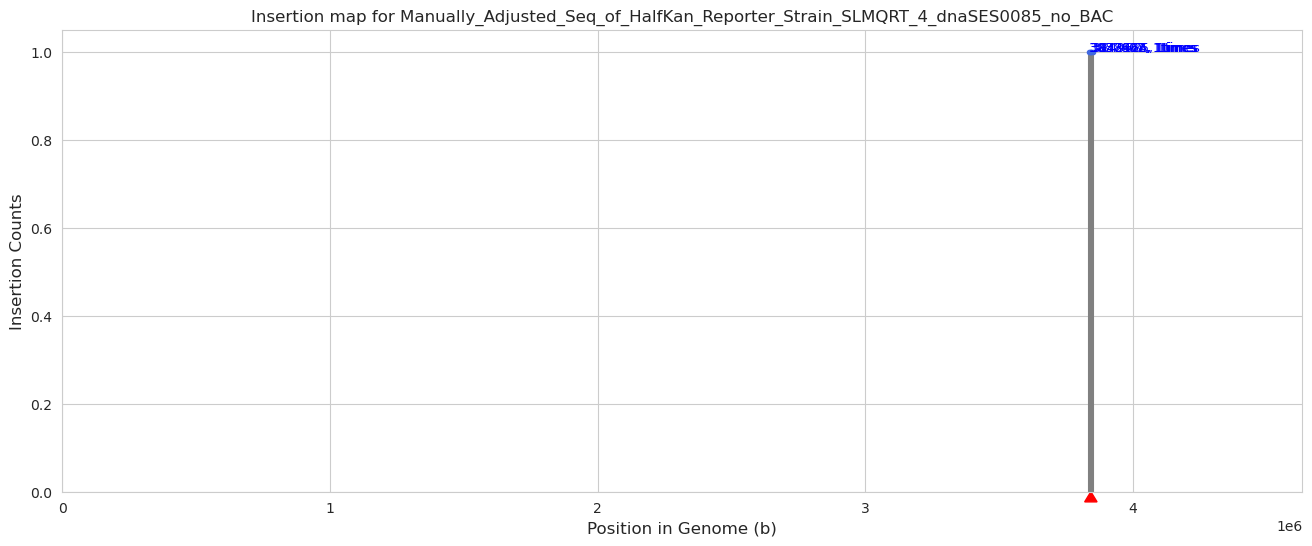

  - Found 356 sites with counts >= 0 to label.


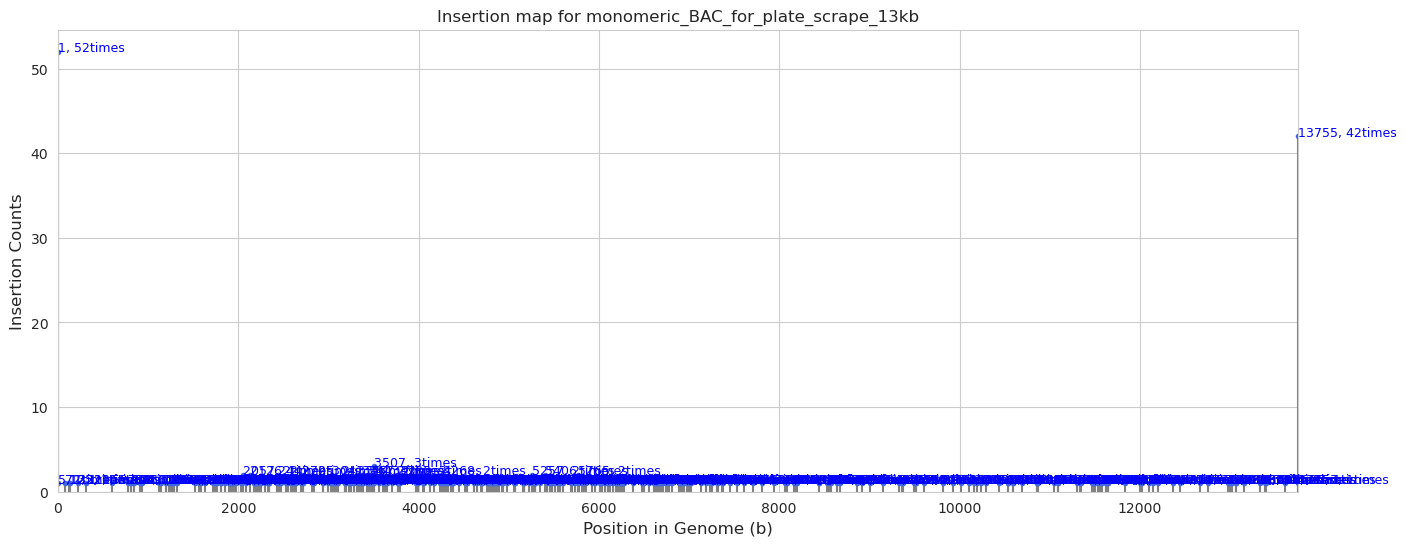

In [ ]:
print("\nStep 5: Creating genome-wide plots...")
##### Make the high level insertion map
reference_genome_name = "Manually_Adjusted_Seq_of_HalfKan_Reporter_Strain_SLMQRT_4_dnaSES0085_no_BAC"

for reference in count_df_fullreads["reference"].unique():

    ax = plot_insertions(
        count_df_fullreads[count_df_fullreads["reference"]==reference], 
        gls_full[reference], 
        mode="b")
    if reference == reference_genome_name:
        plot_triangle(args.target_coordinate, ax)
    ax.set_title(args.title, fontsize=16)
    ax.set_xlabel("Position in Genome (b)", fontsize=12)
    plt.title(f"Insertion map for {reference}")
    plt.show()
    # plt.savefig(os.path.join(out_dir, "alignment_plot.png"), dpi=300)


Plotting insertion map with coverage...
  - Found 5 sites with counts >= 0 to label.


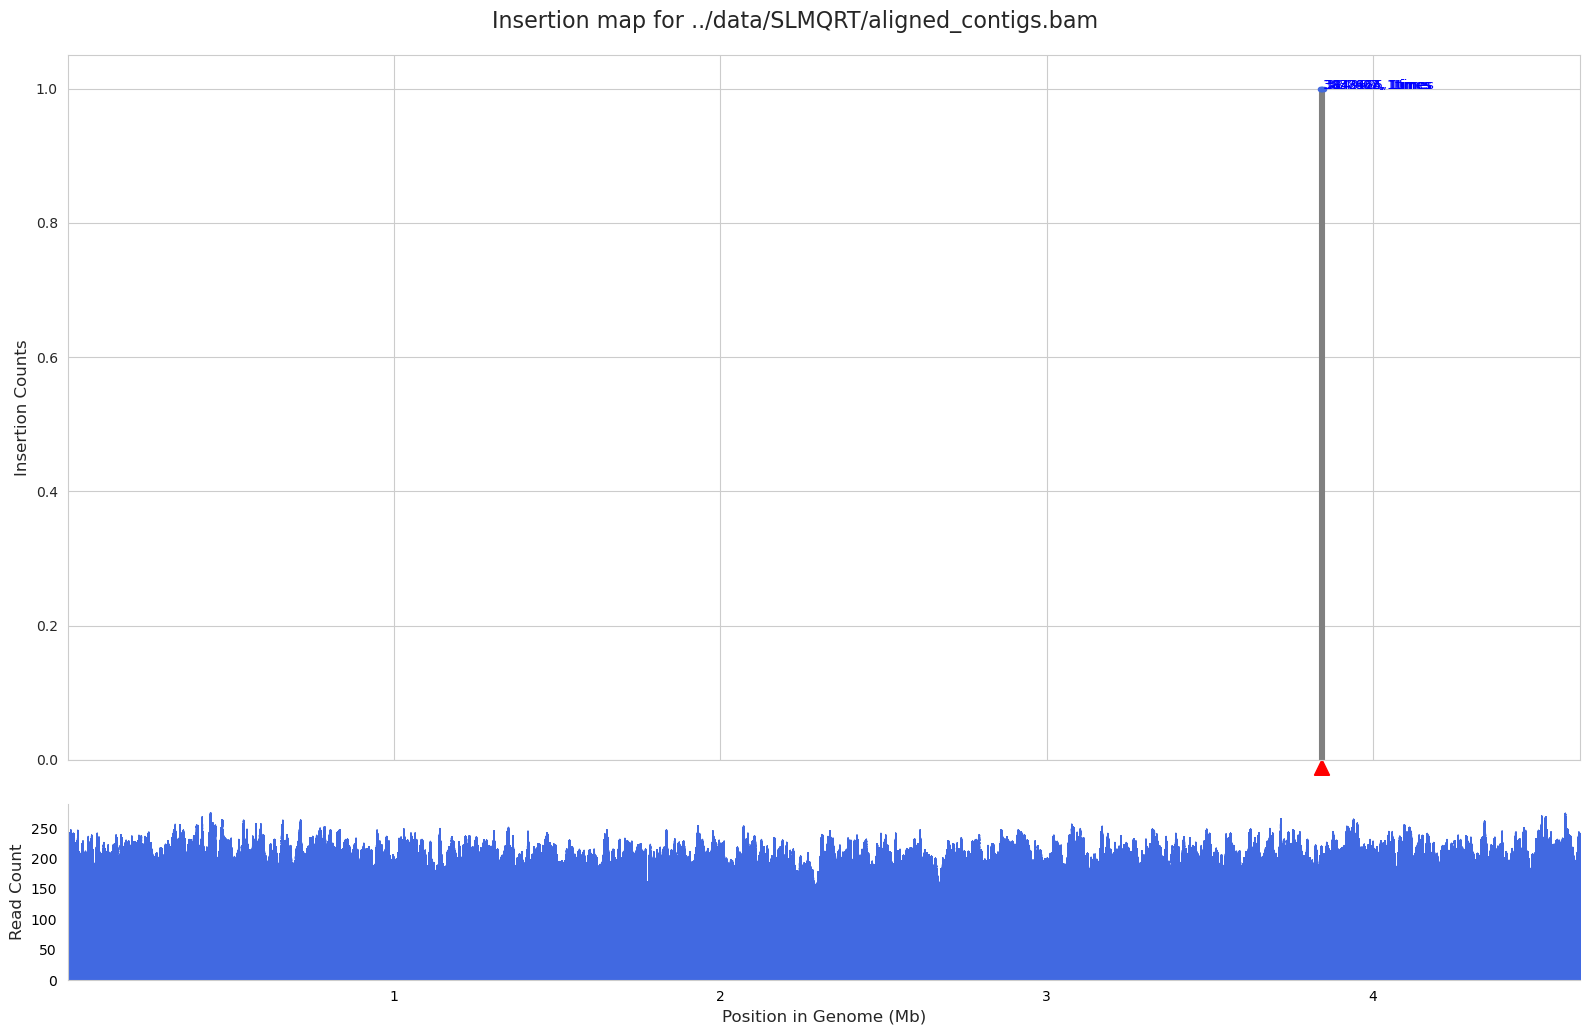

Plotting zoomed in insertion map...
  - Found 1 sites with counts >= 0 to label.


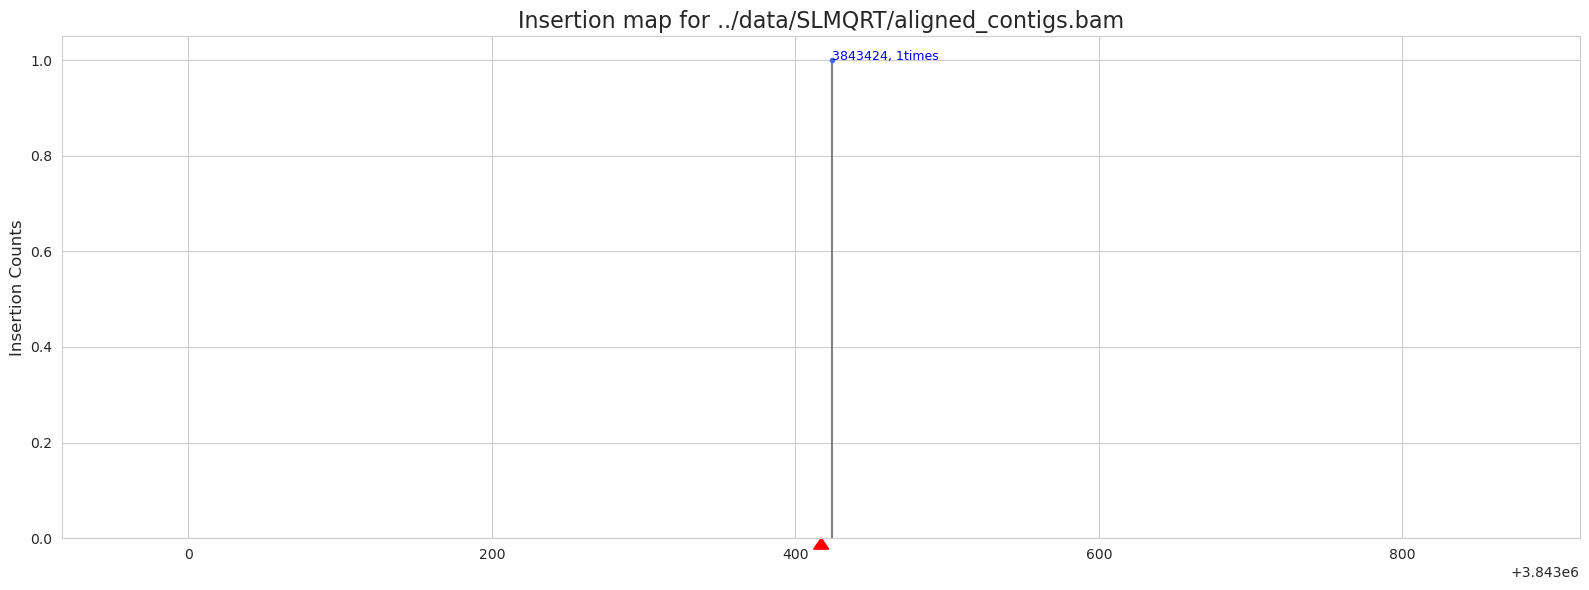

Plotting pie chart...


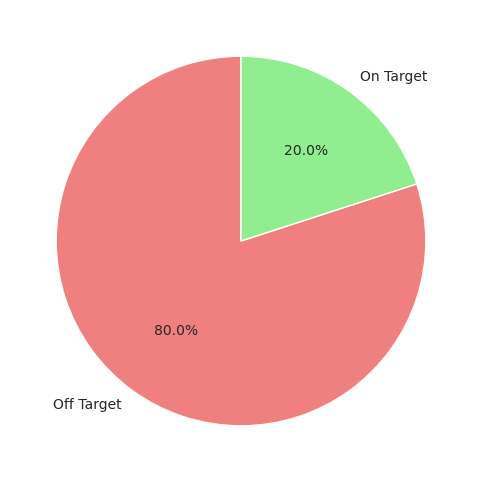

In [ ]:
if args.plot_coverage:
    print("Plotting insertion map with coverage...")
    counts_df_reference = count_df_fullreads[count_df_fullreads["reference"]==reference_genome_name].copy()
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True, gridspec_kw={'height_ratios': [4, 1]})
    plot_insertions(counts_df_reference, total_genome_lengths[reference_genome_name], mode="mb", ax=ax1)
    plot_triangle(args.target_coordinate / 1_000_000, ax1) # Plot triangle at target site

    # Read dataframe of whole genome coverage
    cov_df = pd.read_csv((os.path.join(args.wk_dir, "raw_reads_coverage.tsv")), sep="\t", header=None)
    cov_df.columns=["chrom", "pos", "depth"]
    cov_df["pos_mb"] = cov_df["pos"] / 1_000_000
    # Subset to only reference genome
    cov_df_ref = cov_df[cov_df["chrom"]==reference_genome_name].copy()
    # Plot coverage below insetion map
    ax2.fill_between(cov_df_ref['pos_mb'], cov_df_ref['depth'], color='royalblue')
    ax2.set_ylabel("Read Count", fontsize=12)
    ax2.set_xlabel("Position in Genome (Mb)", fontsize=12)
    ax2.set_ylim(bottom=0)
    ax2.set_xlim(cov_df_ref["pos_mb"].min(), cov_df_ref["pos_mb"].max())
    ax2.tick_params(
        direction='out',
        length=4,
        width=1,
        colors='black',
        grid_color='none',
        grid_alpha=0.5
    )
    sns.despine(ax=ax2)

    # --- Layout adjustment ---
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.1)  # Increase vertical space between plots
    plt.suptitle(args.title, fontsize=16, y=1.03)
    # fig.savefig(os.path.join(out_dir, "alignment_plot_with_coverage.png"), dpi=300)
    plt.show()
# If target coordinate provided: save an additional zoomed in plot around 
# that site AND save a pie chart of on target % (on target is defined as 
# give or take args.on_target_threshold from target site [defaults to 10bp])

if args.target_coordinate:
    print("Plotting zoomed in insertion map...")
    # PLOT A ZOOMED IN VERSION OF THE INSERTION MAP
    w = 1000 / 2
    xmin, xmax = args.target_coordinate - w, args.target_coordinate + w

    ax = plot_insertions(
        counts_df_reference[(counts_df_reference["position"] >= xmin) & (counts_df_reference["position"] <= xmax)], 
        total_genome_lengths[reference_genome_name],
        mode="b")
    plt.xlim(xmin, xmax)
    plot_triangle(args.target_coordinate, ax)
    plt.title(args.title, fontsize=16)
    plt.tight_layout()
    plt.show()
    # plt.savefig(os.path.join(out_dir, "alignment_plot_zoomed.png"), dpi=300)

    # PLOT A PIE CHART SHOWING % OF ON TARGET INTEGRATIONS
    print("Plotting pie chart...")
    def on_target_mapper(pos):
        if (pos >= (args.target_coordinate - args.on_target_threshold)) and (pos <= args.target_coordinate + args.on_target_threshold ):
            return True
        else:
            return False

    counts_df_reference["on_target"] = counts_df_reference["position"].map(on_target_mapper)
    counts = counts_df_reference.groupby('on_target')['count'].sum()
    # Plot pie chart
    plt.figure(figsize=(6, 6))
    counts.plot.pie(
        autopct='%1.1f%%',
        startangle=90,
        labels=['Off Target', 'On Target'],  # Map False to Off, True to On
        colors=['lightcoral', 'lightgreen'],
        # wedgeprops={'edgecolor': 'black'}
    )
    plt.ylabel("")
    plt.show()
    # plt.savefig(os.path.join(out_dir, "on_target_pie_chart.png"), dpi=300)

In [ ]:
counts_df_reference

,reference,position,count,position_mb,on_target
0,Manually_Adjusted_Seq_of_HalfKan_Reporter_Stra...,3837607,1,3.837607,False
1,Manually_Adjusted_Seq_of_HalfKan_Reporter_Stra...,3838952,1,3.838952,False
2,Manually_Adjusted_Seq_of_HalfKan_Reporter_Stra...,3842566,1,3.842566,False
3,Manually_Adjusted_Seq_of_HalfKan_Reporter_Stra...,3843424,1,3.843424,True
4,Manually_Adjusted_Seq_of_HalfKan_Reporter_Stra...,3849685,1,3.849685,False
